# 07 – File formats in the lake (Spark)

**Goal (Task 4, part 1):**
1. Start a **Spark session in local mode** with PySpark.
2. Read the **Parquet file of the full load** (notebook 01) from the lake.
3. Write the same data back to the lake as **CSV, JSON, Avro and Parquet**, with different **compression** and **partitioning** settings, and compare the **file sizes**.
4. Read every version back and compare the **content and schema (data types)**.
5. Look **inside** one Avro file and one Parquet file.

| Format | Stores data by | Schema inside the file? | Types | Human-readable |
|---|---|---|---|---|
| CSV | row (text) | no (only a header) | everything is text | yes |
| JSON | row (text) | no (field names in every row) | string / number / boolean | yes |
| Avro | **row** (binary) | **yes**, in the header | yes | no |
| Parquet | **column** (binary) | **yes**, in the footer | yes | no |

## Step 1 – Spark session (local mode)

`get_spark()` (in `spark_pile.py`) starts Spark with `master("local[*]")`: Spark runs **inside this container** and uses all CPU cores, with no cluster.
The first start downloads two extra packages from Maven (`spark-avro` for Avro, `hadoop-aws` for `s3a://` = Silo), which takes about a minute.

In [1]:
import pandas as pd
from pyspark.sql import functions as F
from spark_pile import get_spark, list_files, copy_to_local, LAKE_URI

spark = get_spark("07-file-formats")
print("Spark", spark.version, "| master:", spark.sparkContext.master, "| lake:", LAKE_URI)
print("Spark UI: http://localhost:4040")

:: loading settings :: url = jar:file:/opt/conda/lib/python3.13/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/jovyan/.ivy2.5.2/cache
The jars for the packages stored in: /home/jovyan/.ivy2.5.2/jars
org.apache.spark#spark-avro_2.13 added as a dependency
org.apache.hadoop#hadoop-aws added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-c313779d-9bef-4b15-9148-8d76cc522c18;1.0
	confs: [default]
	found org.apache.spark#spark-avro_2.13;4.0.1 in central
	found org.scala-lang.modules#scala-parallel-collections_2.13;1.2.0 in central
	found org.tukaani#xz;1.10 in central
	found org.apache.hadoop#hadoop-aws;3.4.1 in central
	found software.amazon.awssdk#bundle;2.24.6 in central
	found org.wildfly.openssl#wildfly-openssl;1.1.3.Final in central
downloading https://repo1.maven.org/maven2/org/apache/spark/spark-avro_2.13/4.0.1/spark-avro_2.13-4.0.1.jar ...
	[SUCCESSFUL ] org.apache.spark#spark-

Spark 4.0.1 | master: local[*] | lake: s3a://pawhome-lake
Spark UI: http://localhost:4040


## Step 2 – Read the Parquet file of the full load

Notebook 01 (Task 2) wrote `postgres/animals/ingestion_date=<date>/<load_id>.<file_id>.parquet` into the lake bucket `pawhome-lake`.

In [2]:
source_files = [name for name, size in list_files(spark, f"{LAKE_URI}/postgres/animals") if name.endswith(".parquet")]
source_path = f"{LAKE_URI}/postgres/animals/{source_files[-1]}"
print("Reading:", source_path)

animals = spark.read.parquet(source_path)
print("Rows:", animals.count(), "| partitions in Spark:", animals.rdd.getNumPartitions())
animals.printSchema()

SLF4J: Failed to load class "org.slf4j.impl.StaticLoggerBinder".
SLF4J: Defaulting to no-operation (NOP) logger implementation
SLF4J: See http://www.slf4j.org/codes.html#StaticLoggerBinder for further details.


Reading: s3a://pawhome-lake/postgres/animals/ingestion_date=2026-10-29/1793305288.0328362.af8c56d765.parquet
Rows: 3000 | partitions in Spark: 1
root
 |-- id: long (nullable = true)
 |-- shelter_id: long (nullable = true)
 |-- name: string (nullable = true)
 |-- species: string (nullable = true)
 |-- breed: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- age_years: decimal(4,1) (nullable = true)
 |-- size: string (nullable = true)
 |-- is_vaccinated: boolean (nullable = true)
 |-- status: string (nullable = true)
 |-- arrived_at: date (nullable = true)
 |-- description: string (nullable = true)
 |-- _source_system: string (nullable = true)
 |-- _source_resource: string (nullable = true)
 |-- _ingestion_type: string (nullable = true)
 |-- _ingested_at: timestamp (nullable = true)
 |-- _load_id: string (nullable = true)
 |-- _dlt_load_id: string (nullable = true)
 |-- _dlt_id: string (nullable = true)



## Step 3 – Write the data in different formats

Everything goes to `pawhome-lake/spark/formats/animals/<variant>/`. Spark always writes a **folder** with one or more `part-*` files (one per partition) and a `_SUCCESS` marker.

**Compression settings** (`option("compression", ...)`):
- CSV / JSON: `none`, `gzip`
- Avro: `uncompressed`, `snappy`, `deflate`
- Parquet: `none`, `snappy` (Spark's default), `gzip`, `zstd`

In [3]:
OUT = f"{LAKE_URI}/spark/formats/animals"

FORMAT_VARIANTS = [
    # name               format     options
    ("csv",              "csv",     {"header": "true", "compression": "none"}),
    ("csv_gzip",         "csv",     {"header": "true", "compression": "gzip"}),
    ("json",             "json",    {"compression": "none"}),
    ("json_gzip",        "json",    {"compression": "gzip"}),
    ("avro",             "avro",    {"compression": "uncompressed"}),
    ("avro_snappy",      "avro",    {"compression": "snappy"}),
    ("avro_deflate",     "avro",    {"compression": "deflate"}),
    ("parquet",          "parquet", {"compression": "none"}),
    ("parquet_snappy",   "parquet", {"compression": "snappy"}),
    ("parquet_gzip",     "parquet", {"compression": "gzip"}),
    ("parquet_zstd",     "parquet", {"compression": "zstd"}),
]

for name, fmt, options in FORMAT_VARIANTS:
    animals.write.mode("overwrite").format(fmt).options(**options).save(f"{OUT}/{name}")
    print("written", name)

written csv
written csv_gzip
written json
written json_gzip
written avro
written avro_snappy
written avro_deflate
written parquet
written parquet_snappy
written parquet_gzip
written parquet_zstd


### Partitioning options

- `repartition(n)` → shuffles the rows into **n** Spark partitions → **n files**
- `coalesce(1)` → merges partitions **without a shuffle** → 1 file
- `partitionBy("species")` → one **folder per value**: `species=dog/`, `species=cat/` … (the column is moved into the folder name)
- `repartition("species")` + `partitionBy("species")` → exactly one file per folder

In [4]:
PARTITION_VARIANTS = [
    # name                                      how the DataFrame is split      partitionBy
    ("parquet_coalesce_1",                      lambda d: d.coalesce(1),        None),
    ("parquet_repartition_4",                   lambda d: d.repartition(4),     None),
    ("parquet_partitionBy_species",             lambda d: d.repartition(3),     ["species"]),
    ("parquet_repartition_partitionBy_species", lambda d: d.repartition("species"), ["species"]),
]

for name, split, partition_cols in PARTITION_VARIANTS:
    writer = split(animals).write.mode("overwrite").option("compression", "snappy")
    if partition_cols:
        writer = writer.partitionBy(*partition_cols)
    writer.parquet(f"{OUT}/{name}")
    print("written", name)

written parquet_coalesce_1
written parquet_repartition_4
written parquet_partitionBy_species
written parquet_repartition_partitionBy_species


## Step 4 – Check the results: files and sizes

In [5]:
def data_files_of(variant):
    return [(n, s) for n, s in list_files(spark, f"{OUT}/{variant}")
            if not n.split("/")[-1].startswith((".", "_"))]          # skip _SUCCESS and .crc files

original_kb = sum(s for n, s in list_files(spark, source_path)) / 1024
rows = [{"variant": "original (dlt parquet)", "files": 1, "size_kb": round(original_kb, 1)}]
for name in [v[0] for v in FORMAT_VARIANTS + PARTITION_VARIANTS]:
    files = data_files_of(name)
    rows.append({"variant": name, "files": len(files), "size_kb": round(sum(s for _, s in files) / 1024, 1)})

sizes = pd.DataFrame(rows)
sizes["vs_csv"] = (sizes.size_kb / sizes.loc[sizes.variant == "csv", "size_kb"].iloc[0]).round(2)
sizes

,variant,files,size_kb,vs_csv
0,original (dlt parquet),1,113.3,0.19
1,csv,1,610.1,1.00
2,csv_gzip,1,110.4,0.18
3,json,1,1362.8,2.23
4,json_gzip,1,130.9,0.21
5,avro,1,561.5,0.92
6,avro_snappy,1,171.1,0.28
7,avro_deflate,1,123.0,0.20
8,parquet,1,163.0,0.27
9,parquet_snappy,1,105.9,0.17


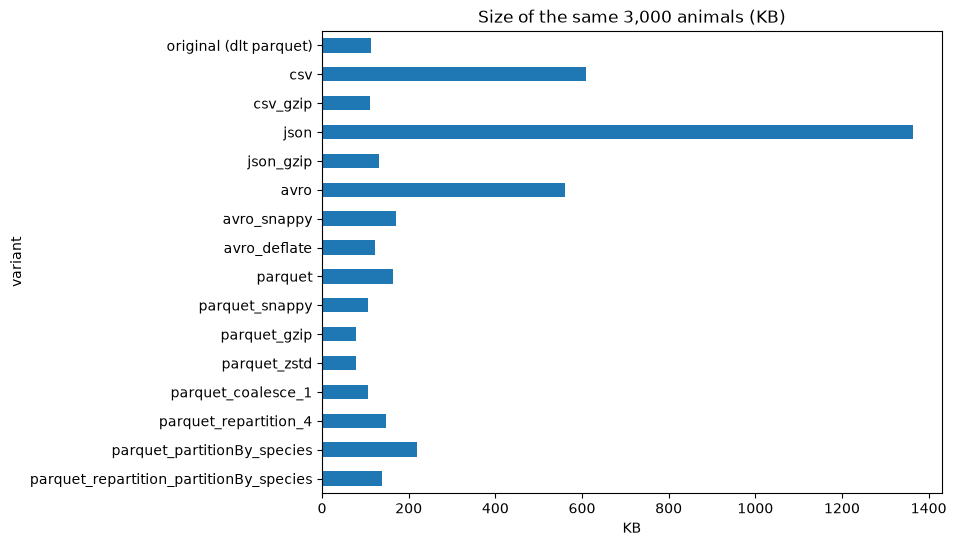

In [6]:
ax = sizes.set_index("variant").size_kb.plot.barh(figsize=(8, 6), title="Size of the same 3,000 animals (KB)")
ax.invert_yaxis(); ax.set_xlabel("KB");

In [7]:
# What does partitionBy look like in the lake? One folder per species:
pd.DataFrame(data_files_of("parquet_repartition_partitionBy_species"), columns=["file", "bytes"])

,file,bytes
0,species=bird/part-00000-d49e2c9f-3ad6-477c-b33...,12776
1,species=cat/part-00000-d49e2c9f-3ad6-477c-b330...,42240
2,species=dog/part-00000-d49e2c9f-3ad6-477c-b330...,56309
3,species=guinea pig/part-00000-d49e2c9f-3ad6-47...,12830
4,species=rabbit/part-00000-d49e2c9f-3ad6-477c-b...,17922


**What to notice**
- Text formats (CSV, JSON) are the **biggest**; JSON is bigger than CSV because **every row repeats the field names**.
- **Compression** makes everything smaller; gzip/zstd/deflate compress more than snappy, but snappy is faster.
- **Parquet** is the smallest: values of one column are stored together, so they compress very well.
- `repartition(4)` → 4 files; `partitionBy("species")` → a folder per species. Too many small files is bad for performance.

## Step 5 – Read everything back and compare the schemas

CSV is read twice: without `inferSchema` (Spark sees only text) and with `inferSchema` (Spark guesses the types by scanning the data).

In [8]:
def read_variant(name, fmt, infer=True):
    path = f"{OUT}/{name}"
    if fmt == "csv":
        return spark.read.option("header", True).option("inferSchema", infer).csv(path)
    return spark.read.format(fmt).load(path)

read_back = {
    "csv (text only)":   read_variant("csv", "csv", infer=False),
    "csv (inferSchema)": read_variant("csv", "csv"),
    "json":              read_variant("json", "json"),
    "avro":              read_variant("avro", "avro"),
    "parquet":           read_variant("parquet_snappy", "parquet"),
}

schema_table = pd.DataFrame(
    {"original": {f.name: f.dataType.simpleString() for f in animals.schema.fields},
     **{label: {f.name: f.dataType.simpleString() for f in df.schema.fields} for label, df in read_back.items()}}
).loc[animals.columns]

def highlight(row):
    return ["" if v == row["original"] else "background-color: #ffe0e0" for v in row]

schema_table.style.apply(highlight, axis=1)

,original,csv (text only),csv (inferSchema),json,avro,parquet
id,bigint,string,int,bigint,bigint,bigint
shelter_id,bigint,string,int,bigint,bigint,bigint
name,string,string,string,string,string,string
species,string,string,string,string,string,string
breed,string,string,string,string,string,string
sex,string,string,string,string,string,string
age_years,"decimal(4,1)",string,double,double,"decimal(4,1)","decimal(4,1)"
size,string,string,string,string,string,string
is_vaccinated,boolean,string,boolean,boolean,boolean,boolean
status,string,string,string,string,string,string


**What to notice** (red = the type changed):
- **CSV** has no types at all → everything is `string`. With `inferSchema` Spark guesses: `decimal` becomes `double`, `id` becomes `int`.
- **JSON** knows only text, numbers and true/false → `date` and `timestamp` become **string**, `decimal` becomes `double`, `long` stays `bigint`. JSON also sorts the columns alphabetically.
- **Avro** and **Parquet** store the schema in the file → the types come back the same.

## Step 6 – Compare the content

Each version is cast back to the original types and joined with the original by `id`. Then, for every column, we count rows whose value is different.

In [9]:
def mismatches(df):
    aligned = df.select([F.col(f.name).cast(f.dataType).alias(f.name) for f in animals.schema.fields])
    joined = animals.alias("o").join(aligned.alias("r"), "id", "full_outer")
    checks = [F.sum(F.when(~F.col(f"o.{c}").eqNullSafe(F.col(f"r.{c}")), 1).otherwise(0)).alias(c)
              for c in animals.columns if c != "id"]
    return joined.agg(*checks).first().asDict()

content = pd.DataFrame({label: mismatches(df) for label, df in read_back.items()})
content.loc["ROWS"] = {label: df.count() for label, df in read_back.items()}
content[content.sum(axis=1) > 0] if (content.drop("ROWS").sum(axis=1) > 0).any() else content

,csv (text only),csv (inferSchema),json,avro,parquet
_ingested_at,3000,3000,3000,0,0
_load_id,0,3000,0,0,0
_dlt_load_id,0,3000,0,0,0
ROWS,3000,3000,3000,3000,3000


In [10]:
# Why do timestamps differ in CSV / JSON? Spark writes them as TEXT with milliseconds only (.SSS):
(animals.select("id", F.col("_ingested_at").cast("string").alias("original (microseconds)"))
 .join(read_back["csv (text only)"].select(F.col("id").cast("long").alias("id"),
                                         F.col("_ingested_at").alias("as text in the CSV")), "id")
 .show(2, truncate=False))

# Why does inferSchema break _load_id? It LOOKS like a number, so Spark guessed double:
(animals.select("id", "_load_id")
 .join(read_back["csv (inferSchema)"].select(F.col("id").cast("long").alias("id"),
                                           F.col("_load_id").alias("inferSchema read it as")), "id")
 .show(2, truncate=False))

+---+--------------------------+------------------------+
|id |original (microseconds)   |as text in the CSV      |
+---+--------------------------+------------------------+
|729|2026-10-29 20:21:27.915269|2026-10-29T20:21:27.915Z|
|790|2026-10-29 20:21:27.915269|2026-10-29T20:21:27.915Z|
+---+--------------------------+------------------------+
only showing top 2 rows
+---+------------------+----------------------+
|id |_load_id          |inferSchema read it as|
+---+------------------+----------------------+
|729|1793305288.0328362|1.7933052880328362E9  |
|790|1793305288.0328362|1.7933052880328362E9  |
+---+------------------+----------------------+
only showing top 2 rows


**What to notice**
- **Parquet** and **Avro**: 0 differences, the round trip is **lossless**.
- **CSV / JSON**: all rows are there, but
  - timestamps lose their **microseconds** (they are written as text with milliseconds),
  - with `inferSchema` Spark **guesses wrong**: `_load_id` (`1795788427.5373216`) looks like a number → `double` → digits are lost,
  - types have to be guessed or cast back by hand.
- That's why lakes store analytical data in **Parquet** (or Avro for row-by-row streaming), not in CSV/JSON.

## Step 7 – Inside an Avro file and a Parquet file

The code in `file_inspect.py` was generated with an AI assistant. It downloads one file from the lake and walks through its bytes.

In [11]:
from file_inspect import inspect_avro, inspect_parquet

avro_file = [n for n, _ in data_files_of("avro_deflate")][0]
parquet_file = [n for n, _ in data_files_of("parquet_snappy")][0]
local_avro = copy_to_local(spark, f"{OUT}/avro_deflate/{avro_file}", "inspect_tmp")
local_parquet = copy_to_local(spark, f"{OUT}/parquet_snappy/{parquet_file}", "inspect_tmp")

### Avro: row-based

`[magic "Obj\x01"] [header: schema as JSON + codec] [sync marker] [block: n rows, size, rows…, sync marker] [block…]`

In [12]:
avro = inspect_avro(local_avro)

AVRO FILE: part-00000-cfc1a47b-1ca7-4b77-ac9a-2e5e27982aab-c000.deflate.avro  (125,977 bytes)
1) magic bytes        : b'Obj\x01'   (every Avro file starts with 'Obj' + version 1)
2) codec (compression): deflate
3) sync marker        : 32e86a1352c7e4eb4d0b15106cc8d647   (16 random bytes, repeated after every block)
4) header size        : 1192 bytes  (the WHOLE schema is stored inside the file)
5) data blocks        : 9 block(s), 3000 rows in total

First 96 bytes of the file:
00000000  4f 62 6a 01 06 16 61 76 72 6f 2e 73 63 68 65 6d  |Obj...avro.schem|
00000010  61 a4 11 7b 22 74 79 70 65 22 3a 22 72 65 63 6f  |a..{"type":"reco|
00000020  72 64 22 2c 22 6e 61 6d 65 22 3a 22 74 6f 70 4c  |rd","name":"topL|
00000030  65 76 65 6c 52 65 63 6f 72 64 22 2c 22 66 69 65  |evelRecord","fie|
00000040  6c 64 73 22 3a 5b 7b 22 6e 61 6d 65 22 3a 22 69  |lds":[{"name":"i|
00000050  64 22 2c 22 74 79 70 65 22 3a 5b 22 6c 6f 6e 67  |d","type":["long|


In [13]:
avro["schema_fields"]      # the schema stored in the file header

,field,avro type
0,id,"[""long"", ""null""]"
1,shelter_id,"[""long"", ""null""]"
2,name,"[""string"", ""null""]"
3,species,"[""string"", ""null""]"
4,breed,"[""string"", ""null""]"
5,sex,"[""string"", ""null""]"
6,age_years,"[{""type"": ""fixed"", ""name"": ""fixed"", ""namespace..."
7,size,"[""string"", ""null""]"
8,is_vaccinated,"[""boolean"", ""null""]"
9,status,"[""string"", ""null""]"


In [14]:
avro["blocks"]             # the data blocks; every block ends with the same sync marker

,block,starts_at_byte,rows,data_bytes,sync_marker_ok
0,0,1192,335,13646,True
1,1,14859,336,13972,True
2,2,28852,334,13975,True
3,3,42848,339,13946,True
4,4,56815,334,13959,True
5,5,70795,333,14020,True
6,6,84836,333,13874,True
7,7,98731,335,13913,True
8,8,112665,321,13291,True


In [15]:
avro["first_records"]      # whole rows, one after another

,id,shelter_id,name,species,breed,sex,age_years,size,is_vaccinated,status,arrived_at,description,_source_system,_source_resource,_ingestion_type,_ingested_at,_load_id,_dlt_load_id,_dlt_id
0,729,50,Oreo,cat,Tonkinese,F,13.8,small,True,available,2026-08-15,House-trained.,postgres,animals,full,2026-10-29 20:21:27.915269+00:00,1793305288.0328362,1793305288.0328362,RSp3yFc3/Dc6Jw
1,790,37,Gus,dog,Airedale Terrier,M,5.3,large,True,available,2025-11-15,Gets along with other pets.,postgres,animals,full,2026-10-29 20:21:27.915269+00:00,1793305288.0328362,1793305288.0328362,dPb7HILna85ptg
2,1349,44,Coco,cat,Selkirk Rex,F,13.4,medium,True,available,2025-10-30,Good with children.,postgres,animals,full,2026-10-29 20:21:27.915269+00:00,1793305288.0328362,1793305288.0328362,8GIXerFHpwzGbg


### Parquet: column-based

`[magic "PAR1"] [row group: column chunk "id", column chunk "name", …] [footer: schema + statistics] [footer length] ["PAR1"]`

In [16]:
parquet = inspect_parquet(local_parquet)

PARQUET FILE: part-00000-fdfa94f4-fccd-4b17-9923-127a84772238-c000.snappy.parquet  (108,434 bytes)
1) magic at start / end : b'PAR1' / b'PAR1'
2) footer (metadata)    : 4,257 bytes, stored at the END of the file
3) written by           : parquet-mr version 1.15.2 (build 859eac165b08f927fa14590c33bc5f476405fb68)
4) rows / columns       : 3000 rows, 19 columns
5) row groups           : 1  (each row group stores every column separately)

First 48 bytes:
00000000  50 41 52 31 15 00 15 8e f7 02 15 80 bc 01 15 8d  |PAR1............|
00000010  a4 9a de 08 1c 15 f0 2e 15 00 15 06 15 08 00 00  |................|
00000020  c7 bb 01 24 03 00 00 00 f0 2e 01 d9 02 00 05 01  |...$............|

Last 48 bytes (end of footer, footer length, 'PAR1'):
0001a762  1c 00 00 1c 00 00 1c 00 00 1c 00 00 1c 00 00 1c  |................|
0001a772  00 00 1c 00 00 1c 00 00 1c 00 00 1c 00 00 1c 00  |................|
0001a782  00 1c 00 00 1c 00 00 00 a1 10 00 00 50 41 52 31  |............PAR1|


In [17]:
parquet["schema"]          # physical type (how it is stored) + logical type (what it means)

,column,physical type,logical type,max definition level
0,id,INT64,None,1
1,shelter_id,INT64,None,1
2,name,BYTE_ARRAY,String,1
3,species,BYTE_ARRAY,String,1
4,breed,BYTE_ARRAY,String,1
5,sex,BYTE_ARRAY,String,1
6,age_years,INT32,"Decimal(precision=4, scale=1)",1
7,size,BYTE_ARRAY,String,1
8,is_vaccinated,BOOLEAN,None,1
9,status,BYTE_ARRAY,String,1


In [18]:
parquet["column_chunks"]   # one chunk per column: compression, encodings, sizes, min/max statistics

,row_group,column,compression,encodings,compressed_bytes,uncompressed_bytes,dictionary_page_at,data_page_at,min,max,nulls
0,0,id,SNAPPY,"PLAIN, RLE, BIT_PACKED",12060,24035,NaN,4,1,3000,0
1,0,shelter_id,SNAPPY,"RLE, BIT_PACKED, PLAIN_DICTIONARY",2529,2711,12064.0,12298,1,50,0
2,0,name,SNAPPY,"RLE, BIT_PACKED, PLAIN_DICTIONARY",2624,2680,14593.0,14922,Ace,Tuffy,0
3,0,species,SNAPPY,"RLE, BIT_PACKED, PLAIN_DICTIONARY",1236,1230,17217.0,17283,bird,rabbit,0
4,0,breed,SNAPPY,"RLE, BIT_PACKED, PLAIN_DICTIONARY",12604,16960,18453.0,27262,Abyssinian,Šarplaninac,0
5,0,sex,SNAPPY,"RLE, BIT_PACKED, PLAIN_DICTIONARY",454,447,31057.0,31088,F,M,0
6,0,age_years,SNAPPY,"RLE, BIT_PACKED, PLAIN_DICTIONARY",3704,3694,31511.0,32170,0.2,16.0,0
7,0,size,SNAPPY,"RLE, BIT_PACKED, PLAIN_DICTIONARY",843,837,35215.0,35263,large,small,0
8,0,is_vaccinated,SNAPPY,"PLAIN, RLE, BIT_PACKED",413,408,NaN,36058,False,True,0
9,0,status,SNAPPY,"RLE, BIT_PACKED, PLAIN_DICTIONARY",853,846,36471.0,36528,adopted,reserved,0


**Avro vs Parquet**

| | Avro | Parquet |
|---|---|---|
| layout | rows one after another, in blocks | each column stored separately (column chunks) |
| schema | JSON in the **header** (start of the file) | in the **footer** (end of the file) |
| statistics | none | min / max / null count per column chunk → whole chunks can be skipped |
| good for | writing row by row, streaming (Kafka) | analytics: read only the columns you need |